# Customer Segmentation - K-Means Clustering

## Objective

Cluster customers into 4 segments aligned with the marketing strategy:

| Segment | Profile | Action |
|---|---|---|
| **VIP** | High spend + high expected spend | VIP program, stop discounts, early access to new products |
| **High-Potential** | High expected spend + low current spend | Top priority for the next campaign - reactivation |
| **Stable Mid** | Medium and stable | Upsell campaigns to raise basket value |
| **Low** | Low spend + low expected spend | Cheap automated campaigns (email only) |

EDA, detailed preprocessing and Total_Spent prediction live in the main project notebook.
This notebook covers clustering only, with the minimal preprocessing needed inside a single pipeline.

## Workflow
1. Load data and select clustering features
2. Preprocess (impute, scale, encode) in one pipeline
3. Choose optimal k (Elbow + Silhouette)
4. Train final K-Means model
5. Profile and label segments


## 1. Load Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 100})
sns.set_style("whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

df = pd.read_csv("marketing_campaign.csv", sep="\t")
print(f"Shape: {df.shape}")
df.head(3)

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0


## 2. Feature Selection & Preprocessing

Features capturing customer behavior and spending, without leaking the target directly.

In [55]:
reference_year = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce").max().year
df["Age"] = reference_year - df["Year_Birth"]
df["TotalCampaignsAccepted"] = (
    df[["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]].sum(axis=1)
)
df["Total_Spent"] = df[["MntWines", "MntFruits", "MntMeatProducts",
                         "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)

num_features = [
    "Age", "Income", "Kidhome", "Teenhome",
    "Recency",
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumWebVisitsMonth",
    "TotalCampaignsAccepted", "Total_Spent"
]
cat_features = ["Education", "Marital_Status"]

X = df[num_features + cat_features].copy()



In [56]:
X["Education"] = X["Education"].replace({"2n Cycle": "Master"})
X["Marital_Status"] = X["Marital_Status"].replace({
"Together": "Married", "Absurd": "Single", "YOLO": "Single", "Alone": "Single"})


In [57]:
PURCHASE_COLS = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

In [58]:
X.loc[~X["Age"].between(18, 100), "Age"] = np.nan
X["Total_Children"] = X["Kidhome"] + X["Teenhome"]
X["Has_Children"] = (X["Total_Children"] > 0).astype(int)
adult_count = X["Marital_Status"].isin(["Married", "Together"]).astype(int) + 1
X["Household_Size"] = adult_count + X["Total_Children"]
X["Total_Purchases"] = X[PURCHASE_COLS].sum(axis=1)

In [59]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts", 
            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

for col in mnt_cols:
    X[col + "_Ratio"] = X[col] / (X["Total_Spent"] + 1e-6)

X.drop(columns=mnt_cols, inplace=True)

In [60]:
X.drop(columns=["Kidhome", "Teenhome", "Marital_Status"], inplace=True)

In [47]:
mask = X["Income"].fillna(0) < 200_000
X = X[mask].reset_index(drop=True)
df = df[mask].reset_index(drop=True)

print(f"Rows used for clustering: {len(X):,}")
X.head(3)

Rows used for clustering: 2,239


,Age,Income,Kidhome,Teenhome,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,...,Total_Children,Has_Children,Household_Size,Total_Purchases,MntWines_Ratio,MntFruits_Ratio,MntMeatProducts_Ratio,MntFishProducts_Ratio,MntSweetProducts_Ratio,MntGoldProds_Ratio
0,57.0,58138.0,0,0,58,3,8,10,4,7,...,0,0,1,25,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422
1,60.0,46344.0,1,1,38,2,1,1,2,5,...,2,1,3,6,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222
2,49.0,71613.0,0,0,26,1,8,2,10,4,...,0,0,2,21,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124


In [61]:
X.columns

Index(['Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'TotalCampaignsAccepted', 'Total_Spent', 'Education', 'Total_Children',
       'Has_Children', 'Household_Size', 'Total_Purchases', 'MntWines_Ratio',
       'MntFruits_Ratio', 'MntMeatProducts_Ratio', 'MntFishProducts_Ratio',
       'MntSweetProducts_Ratio', 'MntGoldProds_Ratio'],
      dtype='object')

In [62]:
X.drop(columns=['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases'], inplace=True)

In [63]:
num_features = [
    "Age", "Income", "Recency", "NumWebVisitsMonth", 
    "TotalCampaignsAccepted", "Total_Spent", "Total_Purchases", 
    "Total_Children", "Household_Size", "Has_Children",
    "MntWines_Ratio", "MntFruits_Ratio", "MntMeatProducts_Ratio", 
    "MntFishProducts_Ratio", "MntSweetProducts_Ratio", "MntGoldProds_Ratio"
]

cat_features = ["Education"]

## 2.1 Preprocessing Pipeline

K-Means is scale-sensitive, so numerics are standardized and categoricals one-hot encoded.

In [64]:
numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features),
])

X_processed = preprocessor.fit_transform(X)
print(f"Feature matrix after preprocessing: {X_processed.shape}")

Feature matrix after preprocessing: (2239, 20)


## 4. Optimal k (Elbow + Silhouette)

k=2  inertia=29,885  silhouette=0.219
k=3  inertia=24,999  silhouette=0.201
k=4  inertia=23,045  silhouette=0.150
k=5  inertia=21,975  silhouette=0.133
k=6  inertia=20,914  silhouette=0.131
k=7  inertia=20,105  silhouette=0.124
k=8  inertia=19,414  silhouette=0.126
k=9  inertia=18,905  silhouette=0.118
k=10  inertia=18,436  silhouette=0.127


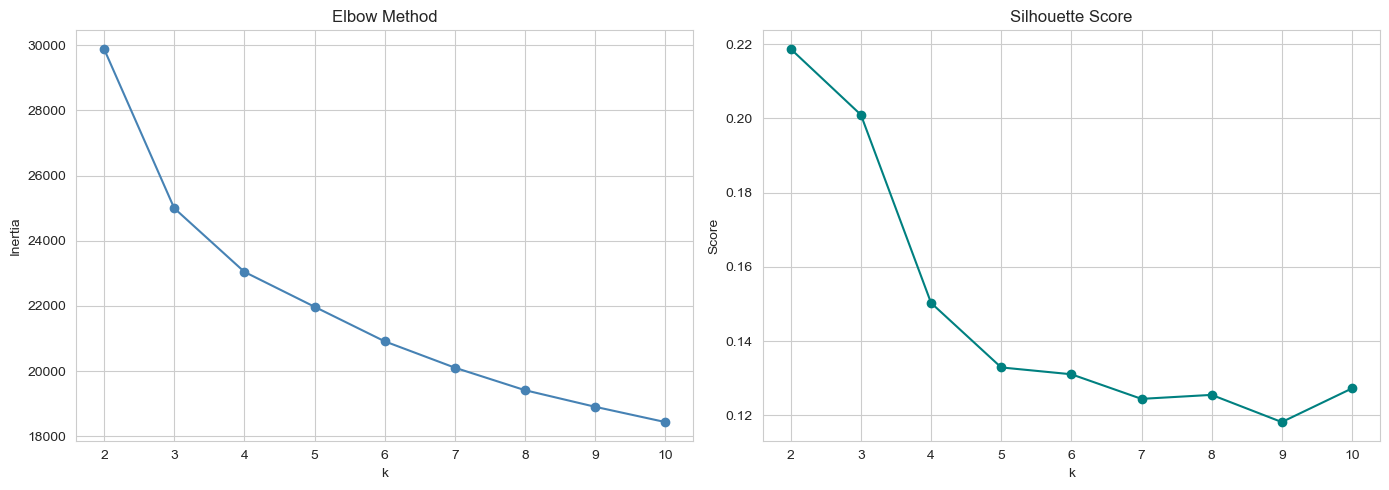

In [65]:
inertias, silhouette_scores, k_range = [], [], range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_processed)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_processed, labels))
    print(f"k={k}  inertia={km.inertia_:,.0f}  silhouette={silhouette_scores[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, "o-", color="steelblue")
axes[0].set_title("Elbow Method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), silhouette_scores, "o-", color="teal")
axes[1].set_title("Silhouette Score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

In [66]:
# k=4 chosen to match the four-segment marketing strategy
# If k=4 silhouette is clearly worse than k=3, fall back to k=3 and merge Stable Mid with Low
BEST_K = 4
print(f"Chosen k = {BEST_K}")

Chosen k = 4


## 5. Final Model + PCA Visualization

Cluster sizes:
Cluster
0    622
1    435
2    511
3    671
Name: count, dtype: int64


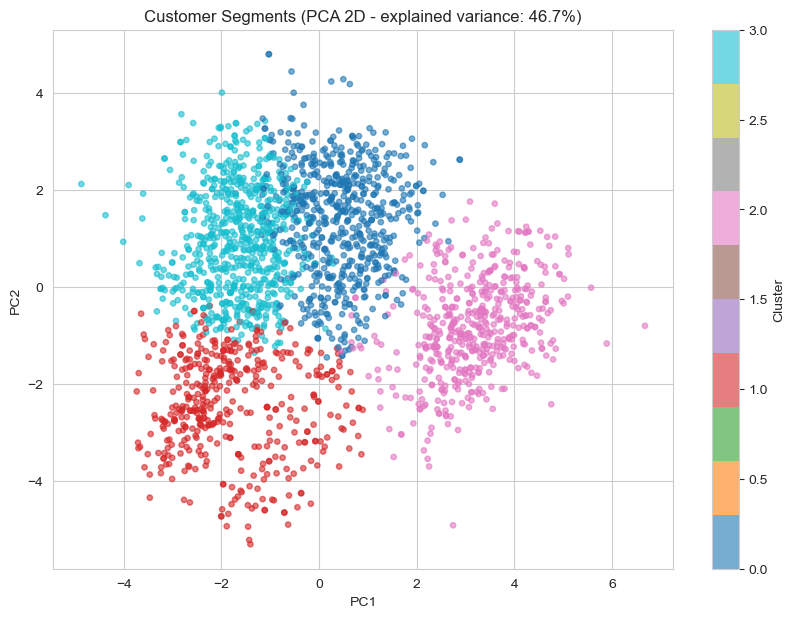

In [67]:
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_processed)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["Cluster"], cmap="tab10", s=15, alpha=0.6)
plt.colorbar(scatter, label="Cluster")
plt.title(f"Customer Segments (PCA 2D - explained variance: {pca.explained_variance_ratio_.sum():.1%})")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

## 6. Cluster Profiling

In [68]:
X["Cluster"] = df["Cluster"] 

profile_features = [
    "Age", "Income", "Recency", "NumWebVisitsMonth", 
    "TotalCampaignsAccepted", "Total_Spent", "Total_Purchases", 
    "Total_Children", "Household_Size", 
    "MntWines_Ratio", "MntFruits_Ratio", "MntMeatProducts_Ratio", 
    "MntFishProducts_Ratio", "MntSweetProducts_Ratio", "MntGoldProds_Ratio"
]

profile = X.groupby("Cluster")[profile_features].mean().round(2)
profile["Size"] = X["Cluster"].value_counts().sort_index()

profile = profile[["Size"] + profile_features]
profile

,Size,Age,Income,Recency,NumWebVisitsMonth,TotalCampaignsAccepted,Total_Spent,Total_Purchases,Total_Children,Household_Size,MntWines_Ratio,MntFruits_Ratio,MntMeatProducts_Ratio,MntFishProducts_Ratio,MntSweetProducts_Ratio,MntGoldProds_Ratio
Cluster,,,,,,,,,,,,,,,,
0,622,49.02,62488.41,48.49,5.38,0.44,851.90,21.59,1.17,2.82,0.61,0.04,0.19,0.05,0.04,0.08
1,435,38.44,28678.63,47.41,6.55,0.17,124.82,8.21,0.79,2.43,0.16,0.11,0.23,0.16,0.11,0.24
2,511,45.77,75821.36,49.72,2.62,1.05,1347.82,19.95,0.01,1.60,0.43,0.05,0.34,0.07,0.05,0.06
3,671,45.26,39182.18,50.36,6.52,0.18,125.20,9.07,1.57,3.24,0.53,0.02,0.25,0.04,0.03,0.13


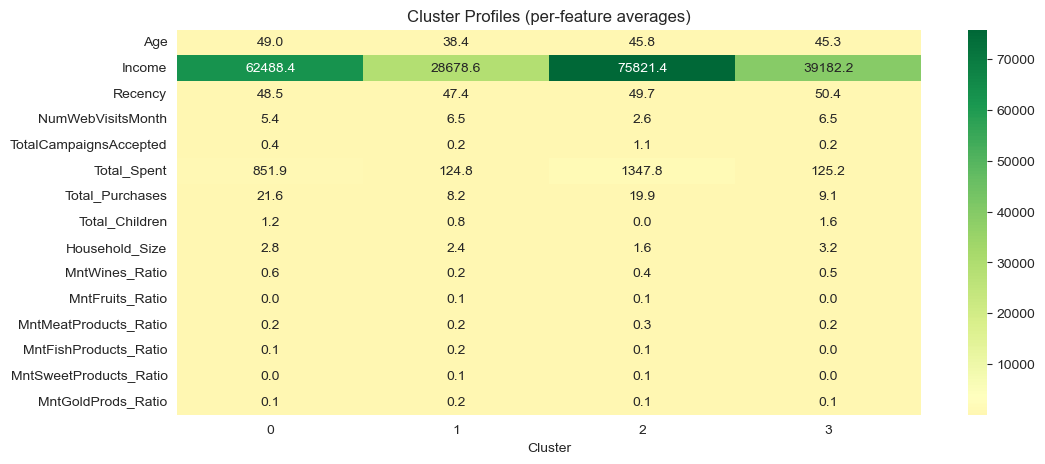

In [69]:
plt.figure(figsize=(12, 5))
sns.heatmap(profile[profile_features].T, annot=True, fmt=".1f", cmap="RdYlGn",
            center=profile[profile_features].mean().mean())
plt.title("Cluster Profiles (per-feature averages)")
plt.show()

## 7. Segment Labeling (Quadrant Strategy)

Each customer is compared against the median of Total_Spent (spending level) and a potential metric (expected level).

In [23]:
# Merge predictions from the regression notebook if its output file exists
# Expected file: predictions.csv with columns ID and Predicted_Spent
import os

if os.path.exists("predictions.csv"):
    preds = pd.read_csv("predictions.csv")
    df = df.merge(preds[["ID", "Predicted_Spent"]], on="ID", how="left")
    df["PotentialMetric"] = df["Predicted_Spent"]
    print("Predictions merged - PotentialMetric = Predicted_Spent")
else:
    # Temporary proxy until real predictions are merged from the prediction notebook
    df["PotentialMetric"] = (
        0.6 * df["Income"].fillna(df["Income"].median())
        + 50 * df["NumCatalogPurchases"]
        + 200 * df["TotalCampaignsAccepted"]
    )
    print("predictions.csv not found - using proxy potential metric (merge later from the prediction notebook)")

predictions.csv not found - using proxy potential metric (merge later from the prediction notebook)


In [70]:
spent_median = df["Total_Spent"].median()
pot_median   = df["PotentialMetric"].median()

print(f"Median Total_Spent = {spent_median:,.0f} | Median Potential = {pot_median:,.0f}\n")

def assign_segment(row):
    high_spend = row["Total_Spent"] >= spent_median
    high_pot   = row["PotentialMetric"] >= pot_median
    if high_spend and high_pot:  return "VIP"
    if not high_spend and high_pot: return "High-Potential"
    if high_spend and not high_pot: return "Stable Mid"
    return "Low"

df["Segment"] = df.apply(assign_segment, axis=1)

segment_summary = df.groupby("Segment").agg(
    Customers=("ID", "count"),
    Avg_Spent=("Total_Spent", "mean"),
    Avg_Income=("Income", "mean"),
    Avg_Potential=("PotentialMetric", "mean"),
    Campaign_Accept_Rate=("TotalCampaignsAccepted", lambda s: (s > 0).mean()),
).round(1)
segment_summary

Median Total_Spent = 396 | Median Potential = 30,924



,Customers,Avg_Spent,Avg_Income,Avg_Potential,Campaign_Accept_Rate
Segment,,,,,
High-Potential,124,206.0,61246.0,36725.8,0.1
Low,993,99.4,32884.6,19918.3,0.2
Stable Mid,126,592.2,43605.5,26511.6,0.3
VIP,996,1162.7,70835.1,42803.9,0.4


## 8. Action Plan

In [71]:
actions = {
    "VIP": "VIP program - stop discounts (they buy without them), early access to new products, personal service",
    "High-Potential": "Top priority: first to receive the next campaign - reactivation, strong welcome offer, direct outreach",
    "Stable Mid": "Upsell campaigns - raise basket value (bundles, cross-sell by favorite category), light loyalty offers",
    "Low": "Cheap automated campaigns (email only) - no meaningful budget, move to low-cost channel",
}

for seg, action in actions.items():
    n = segment_summary.loc[seg, "Customers"] if seg in segment_summary.index else 0
    print(f"{seg}  ({n:,} customers)\n   -> {action}\n")

VIP  (996 customers)
   -> VIP program - stop discounts (they buy without them), early access to new products, personal service

High-Potential  (124 customers)
   -> Top priority: first to receive the next campaign - reactivation, strong welcome offer, direct outreach

Stable Mid  (126 customers)
   -> Upsell campaigns - raise basket value (bundles, cross-sell by favorite category), light loyalty offers

Low  (993 customers)
   -> Cheap automated campaigns (email only) - no meaningful budget, move to low-cost channel



In [26]:
# Save final output for the rest of the project
df[["ID", "Cluster", "Segment", "Total_Spent", "PotentialMetric"]].to_csv("customer_segments.csv", index=False)
print("Saved -> customer_segments.csv")
df["Segment"].value_counts()

Saved -> customer_segments.csv


Segment
VIP               996
Low               993
Stable Mid        126
High-Potential    124
Name: count, dtype: int64

In [72]:
import joblib

In [74]:
model_data = {
    "preprocessor": preprocessor,      
    "model": kmeans,
    "num_features": num_features,
    "cat_features": cat_features,
    "reference_year": reference_year,  
    "income_cap": 200_000,
    "spent_median": spent_median,      
    "pot_median": pot_median,
}

joblib.dump(model_data, "customer_clustering.pkl")
print("Saved -> customer_clustering.pkl")

Saved -> customer_clustering.pkl
